In [30]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

In [31]:
#========== FUNCTIONS TO PRINT SCORES ==========#

def compute_metrics(labels, pred):
    
    fpr, tpr, thres = roc_curve(labels, pred)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer = fpr[np.nanargmin(np.absolute(fnr - fpr))]
    
    #optimal_index = np.argmax(tpr - fpr)
    #optimal_threshold = thres[optimal_index]

    binary_pred = np.where(pred < -0.5, 0, 1)    
    acc = balanced_accuracy_score(labels, binary_pred)
    
    return rocauc, eer, acc
    
def printmd(string):
    display(Markdown(string))

def print_results(model_names, dataset_list):
    if isinstance(model_names, str):
        model_names = [model_names]

    all_scores = {}

    for dataset in dataset_list:
        dataset_name = os.path.basename(dataset)
        output = f"### {dataset_name.upper()} DATASET\n\n"
        scores = []

        for model_name in model_names:
            result_list = glob(os.path.join(dataset, f"{model_name}.txt"))

            for result in result_list:
                df = pd.read_csv(result, header=None, sep=' ')
                df = df.rename(columns={0: 'path', 1: 'score', 2: 'label'})

                rocauc, eer, bal_acc = compute_metrics(df['label'], df['score']) 

                exp_name = os.path.basename(result)[:-4]
                scores.append({
                    'name': exp_name,
                    'auc': rocauc,
                    'eer': eer,
                    'bal_acc': bal_acc
                })

                if exp_name not in all_scores:
                    all_scores[exp_name] = []
                all_scores[exp_name].append({
                    'dataset': dataset_name,
                    'auc': rocauc,
                    'eer': eer,
                    'bal_acc': bal_acc
                })

        # Best scores
        best_auc = max(scores, key=lambda x: x['auc'])['auc']
        best_eer = min(scores, key=lambda x: x['eer'])['eer']
        best_bal_acc = max(scores, key=lambda x: x['bal_acc'])['bal_acc']

        for s in scores:
            name = s['name']
            auc = s['auc']
            eer = s['eer']
            bal_acc = s['bal_acc']

            auc_str = f"**{auc*100:.2f}**" if auc == best_auc else f"{auc*100:.2f}"
            eer_str = f"**{eer*100:.2f}**" if eer == best_eer else f"{eer*100:.2f}"
            bal_str = f"**{bal_acc*100:.2f}**" if bal_acc == best_bal_acc else f"{bal_acc*100:.2f}"

            output += f"`{name}`\t AUC: {auc_str} \t EER: {eer_str} \t Balanced Acc: {bal_str}\n\n"

        printmd(output)

    return all_scores
        
def print_results_NO_BACC(model_names, dataset_list):
    if isinstance(model_names, str):
        model_names = [model_names]

    #dataset_list = glob('/nas/home/vnegroni/ispl_safe/results/*')
    all_scores = {}  # Store results in a dictionary

    for dataset in dataset_list:
        dataset_name = os.path.basename(dataset)
        output = f"### {dataset_name.upper()} DATASET\n\n"
        scores = []

        for model_name in model_names:
            result_list = glob(os.path.join(dataset, f"{model_name}.txt"))

            for result in result_list:
                df = pd.read_csv(result, header=None, sep=' ')
                df = df.rename(columns={0: 'path', 1: 'score', 2: 'label'})

                rocauc, eer, bal_acc = compute_metrics(df['label'], df['score'])

                exp_name = os.path.basename(result)[:-4]
                scores.append({
                    'name': exp_name,
                    'auc': rocauc,
                    'eer': eer
                })

                # Save to the main dictionary
                if exp_name not in all_scores:
                    all_scores[exp_name] = []
                all_scores[exp_name].append({
                    'dataset': dataset_name,
                    'auc': rocauc,
                    'eer': eer
                })

        best_auc = max(scores, key=lambda x: x['auc'])['auc']
        best_eer = min(scores, key=lambda x: x['eer'])['eer']

        for s in scores:
            name = s['name']
            auc = s['auc']
            eer = s['eer']

            auc_str = f"**{auc*100:.2f}**" if auc == best_auc else f"{auc*100:.2f}"
            eer_str = f"**{eer*100:.2f}**" if eer == best_eer else f"{eer*100:.2f}"

            output += f"`{name}`\t AUC: {auc_str} \t EER: {eer_str}\n\n"

        printmd(output)

    return all_scores


def print_average_results_by_type(all_scores, known_datasets, subset='overall'):
    if subset not in ('known', 'unknown', 'overall'):
        raise ValueError("subset must be 'known', 'unknown', or 'overall'")

    output = f"## AVERAGE METRICS - {subset.upper()}\n\n"
    avg_scores = []

    for model, entries in all_scores.items():
        if subset == 'known':
            filtered = [e for e in entries if e['dataset'] in known_datasets]
        elif subset == 'unknown':
            filtered = [e for e in entries if e['dataset'] not in known_datasets]
        else:
            filtered = entries

        aucs = [e['auc'] for e in filtered]
        eers = [e['eer'] for e in filtered]
        bals = [e['bal_acc'] for e in filtered]

        avg_auc = np.mean(aucs) if aucs else None
        avg_eer = np.mean(eers) if eers else None
        avg_bal = np.mean(bals) if bals else None

        avg_scores.append({
            'model': model,
            'avg_auc': avg_auc,
            'avg_eer': avg_eer,
            'avg_bal': avg_bal
        })

    # Best values
    best_auc = max((s['avg_auc'] for s in avg_scores if s['avg_auc'] is not None), default=None)
    best_eer = min((s['avg_eer'] for s in avg_scores if s['avg_eer'] is not None), default=None)
    best_bal = max((s['avg_bal'] for s in avg_scores if s['avg_bal'] is not None), default=None)

    def fmt(value, best_value, is_best_fmt=True):
        if value is None:
            return "N/A"
        s = f"{value*100:.2f}"
        return f"**{s}**" if is_best_fmt and value == best_value else s

    for s in avg_scores:
        model = s['model']
        auc_str = fmt(s['avg_auc'], best_auc)
        eer_str = fmt(s['avg_eer'], best_eer)
        bal_str = fmt(s['avg_bal'], best_bal)

        output += f"`{model}`\t Avg AUC: {auc_str} \t Avg EER: {eer_str} \t Avg Balanced Acc: {bal_str}\n\n"

    printmd(output)

    
def print_average_results_by_type_NO_BACC(all_scores, known_datasets, subset='overall'):
    """
    subset: one of 'known', 'unknown', 'overall'
    """

    if subset not in ('known', 'unknown', 'overall'):
        raise ValueError("subset must be 'known', 'unknown', or 'overall'")

    output = f"## AVERAGE METRICS - {subset.upper()}\n\n"
    avg_scores = []

    for model, entries in all_scores.items():
        # Filter by subset
        if subset == 'known':
            filtered = [e for e in entries if e['dataset'] in known_datasets]
        elif subset == 'unknown':
            filtered = [e for e in entries if e['dataset'] not in known_datasets]
        else:  # overall
            filtered = entries

        aucs = [e['auc'] for e in filtered]
        eers = [e['eer'] for e in filtered]

        if not aucs:
            avg_auc = None
            avg_eer = None
        else:
            avg_auc = np.mean(aucs)
            avg_eer = np.mean(eers)

        avg_scores.append({
            'model': model,
            'avg_auc': avg_auc,
            'avg_eer': avg_eer
        })

    # Get best scores for formatting (highest AUC, lowest EER)
    best_auc = max((s['avg_auc'] for s in avg_scores if s['avg_auc'] is not None), default=None)
    best_eer = min((s['avg_eer'] for s in avg_scores if s['avg_eer'] is not None), default=None)

    def fmt(value, best_value, is_best_fmt=True):
        if value is None:
            return "N/A"
        s = f"{value*100:.2f}"
        return f"**{s}**" if is_best_fmt and value == best_value else s

    for s in avg_scores:
        model = s['model']
        auc_str = fmt(s['avg_auc'], best_auc)
        eer_str = fmt(s['avg_eer'], best_eer, is_best_fmt=True)

        output += f"`{model}`\t Avg AUC: {auc_str} \t Avg EER: {eer_str}\n\n"

    printmd(output)

In [32]:
def plot_5_expert_weights(npy_path, expert_labels=None, color='blue'):
    weights = np.load(npy_path).flatten()

    if len(weights) != 5:
        print(f"[WARN] Expected 5 experts, got {len(weights)}")

    if expert_labels is None:
        expert_labels = [f"E{i}" for i in range(len(weights))]

    plt.figure(figsize=(6, 4))
    plt.bar(range(len(weights)), weights, color=color)

    plt.xticks(range(len(weights)), expert_labels)
    plt.ylim(0, 1)
    plt.ylabel("Avg Gating Weight")
    plt.title("Average Expert Weights")
    plt.grid(True)
    plt.gca().set_axisbelow(True)

    plt.tight_layout()
    plt.show()

# MoE results on all TARGET data

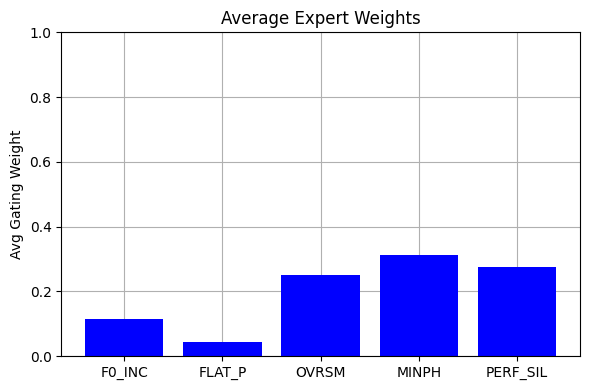

In [53]:
# 3000 bonafide (from EVAL SET) + 3000 deepfake data 
# AUC: 58.19%, EER: 45.12%

#Valid samples: 5824
#Num fake: 2932, Num real: 2892
#Mean score (fake=1): 0.111987   (DEFINITELY TOO LOW!)
#Mean score (real=0): 0.030448

plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/moe_first_trial_5_experts_A03_A04_CUSTOM_gating_mean_global.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL']
)

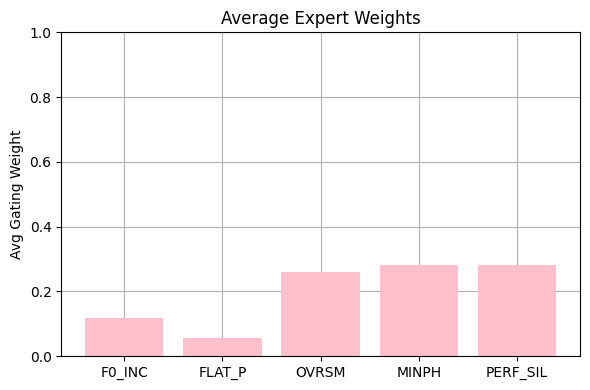

In [54]:
plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/moe_first_trial_5_experts_A03_A04_CUSTOM_gating_mean_real.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'], 
    color='pink'
)

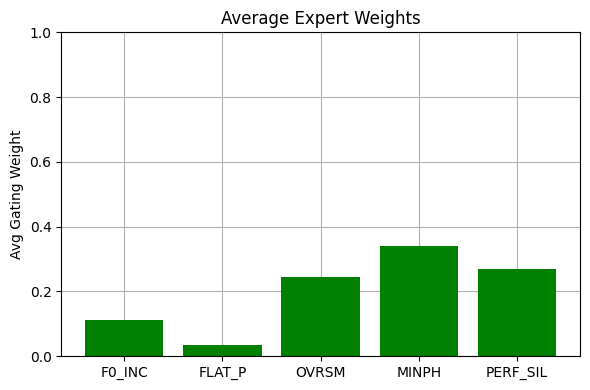

In [55]:
plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/moe_first_trial_5_experts_A03_A04_CUSTOM_gating_mean_fake.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'], 
    color='green'
)

# A04 Only (Target for F0 Inconsistency)

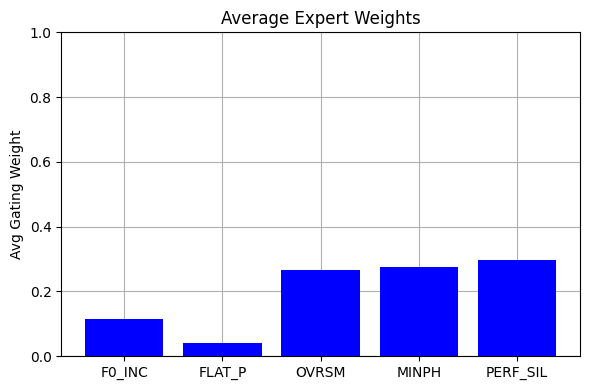

In [56]:
# 1000 bonafide (from EVAL SET) + 1000 deepfake data 
# AUC: 64.90%, EER: 39.43%

#Mean score (fake=1): 0.053146
#Mean score (real=0): 0.022901

plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/moe_first_trial_5_experts_A04_gating_mean_global.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL']
)

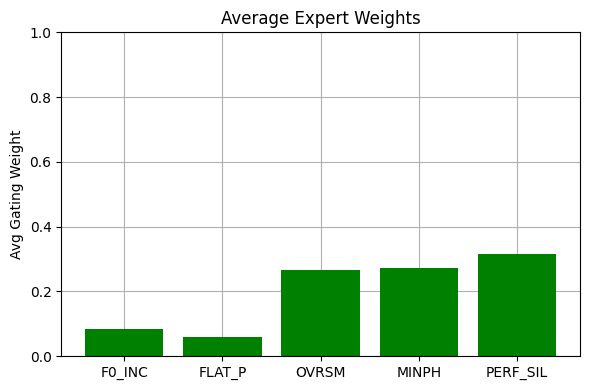

In [58]:
plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/moe_first_trial_5_experts_A04_gating_mean_fake.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'], 
    color='green'
)

# A03 Only (Target for Oversmoothing and Min Phase)

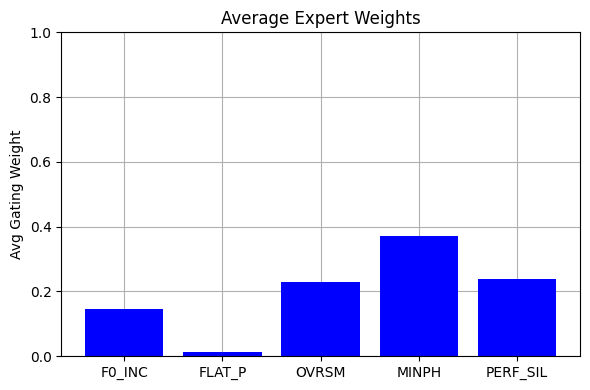

In [59]:
# 1000 bonafide (from EVAL SET) + 1000 deepfake data 
# AUC: 71.07%, EER: 36.13%

#Mean score (fake=1): 0.268233
#Mean score (real=0): 0.022901

plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/moe_first_trial_5_experts_A03_gating_mean_global.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL']
)

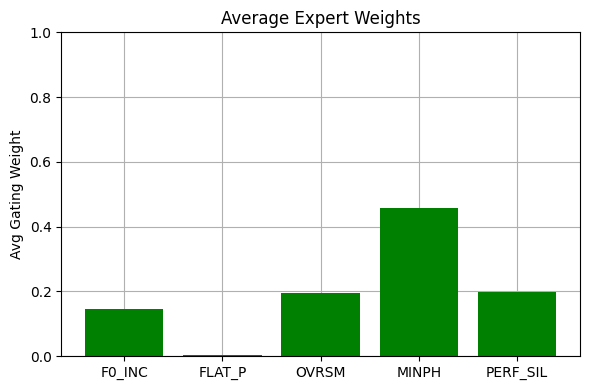

In [60]:
plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/moe_first_trial_5_experts_A03_gating_mean_fake.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'],
    color='green'
)

# CUSTOM Only (Target for Flat Pitch)

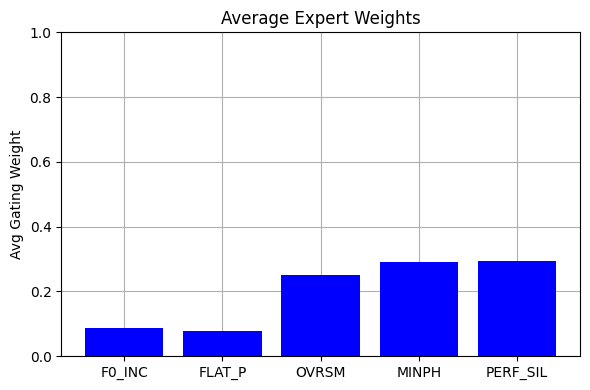

In [63]:
# 1000 bonafide (from EVAL SET) + 1000 deepfake data 
# AUC: 43.63%, EER: 54.60%

#Mean score (fake=1): 0.022366
#Mean score (real=0): 0.035998

plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/moe_first_trial_5_experts_CUSTOM_gating_mean_global.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL']
)

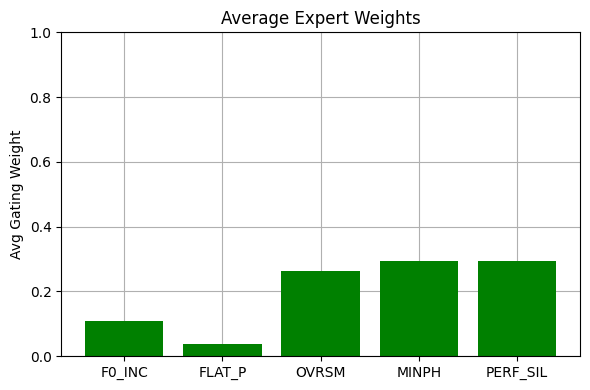

In [64]:
plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/moe_first_trial_5_experts_CUSTOM_gating_mean_fake.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'],
    color='green'
)

# Sanity Checks

## All manipulations applied
1000 real + 1000 manipulated data (from EVAL SET)  
Fakes are fakes for every expert (= every feature is manipulated) -> would expect equal contribution


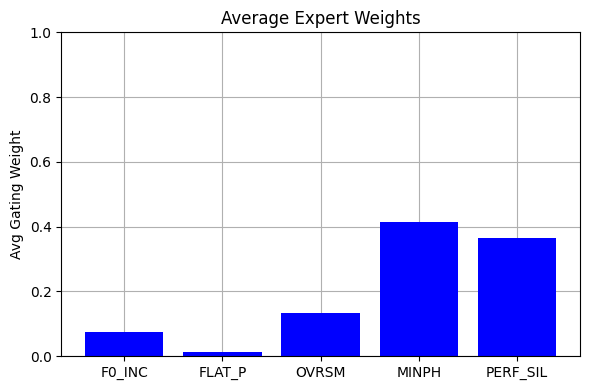

In [36]:
# 1000 bonafide + 1000 manipulated data (from EVAL SET)
# AUC: 99.50%, EER: 1.72%

# Mean score (fake=1): 0.683483 [LOW wrt to the individual checks below (~0.9)]
# Mean score (real=0): 0.030460

plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/moe_first_trial_5_experts_ALL_MANIP_gating_mean_global.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL']
)

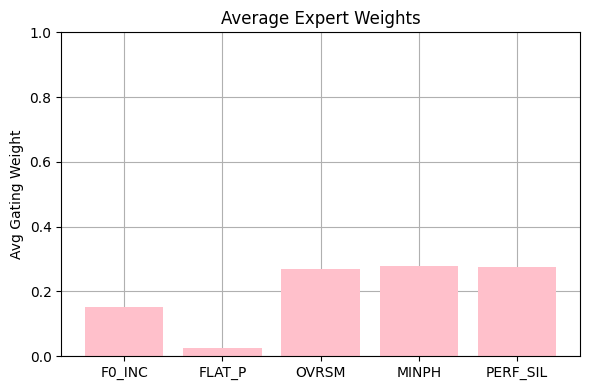

In [38]:
plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/moe_first_trial_5_experts_ALL_MANIP_gating_mean_real.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'],
    color='pink'
)

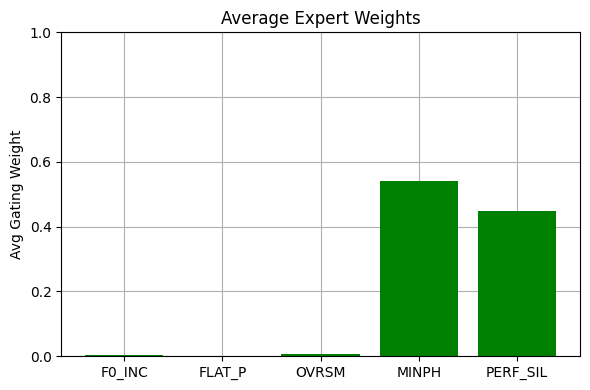

In [39]:
plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/moe_first_trial_5_experts_ALL_MANIP_gating_mean_fake.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'],
    color='green'
)

## One manipulation at a time
Won't show again bar plots for real data as the trend is the same across every scenario

### F0 Inconsistency

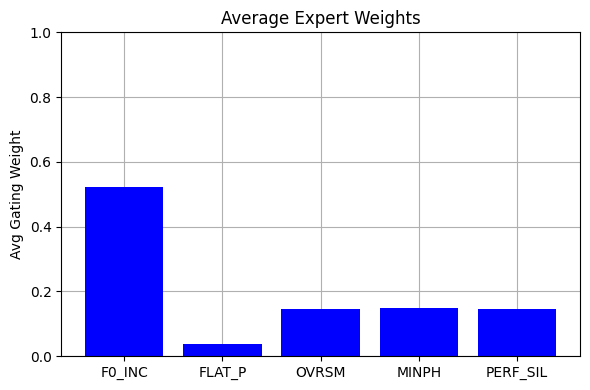

In [40]:
# 1000 bonafide + 1000 manipulated data (from EVAL SET)
# AUC: 98.78%, EER: 3.77%

plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/moe_first_trial_5_experts_F0_INCONS_gating_mean_global.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL']
)

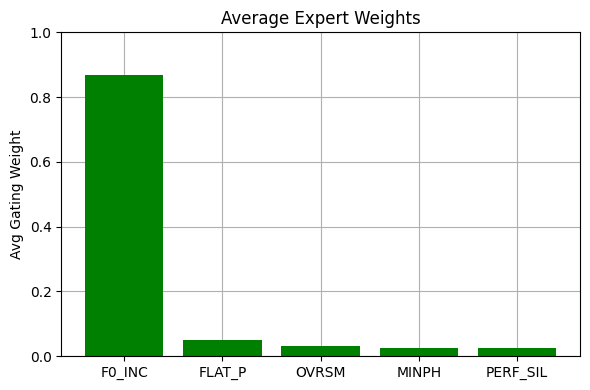

In [42]:
plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/moe_first_trial_5_experts_F0_INCONS_gating_mean_fake.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'], 
    color='green'
)

### Flat Pitch

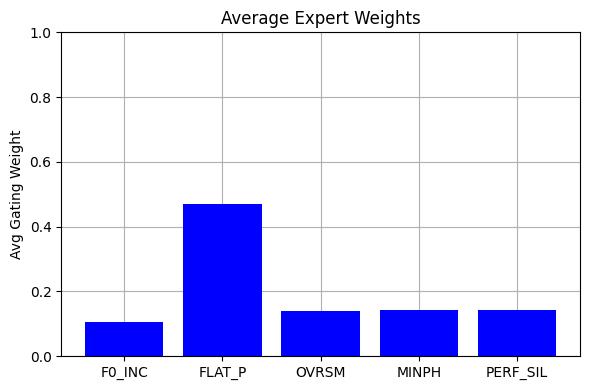

In [43]:
# 1000 bonafide + 1000 manipulated data (from EVAL SET)
# AUC: 99.59%, EER: 1.72%

plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/moe_first_trial_5_experts_FLAT_PITCH_gating_mean_global.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL']
)

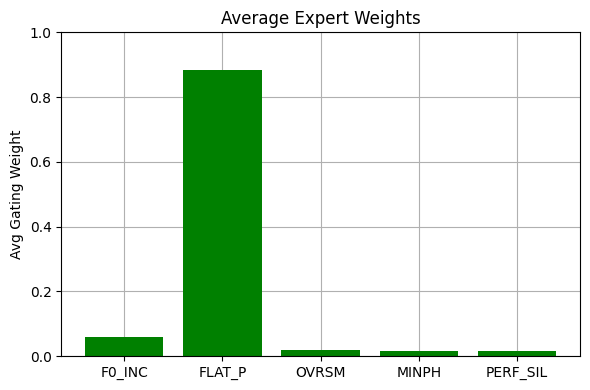

In [45]:
plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/moe_first_trial_5_experts_FLAT_PITCH_gating_mean_fake.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'], 
    color='green'
)

### Oversmoothing

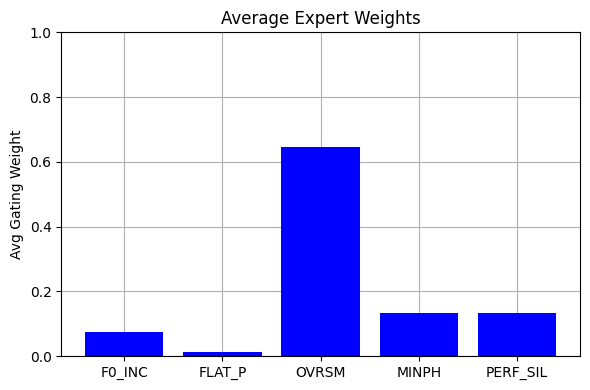

In [46]:
# 1000 bonafide + 1000 manipulated data (from EVAL SET)
# AUC: 99.96%, EER: 0.43%

plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/moe_first_trial_5_experts_OVERSMOOTH_gating_mean_global.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL']
)

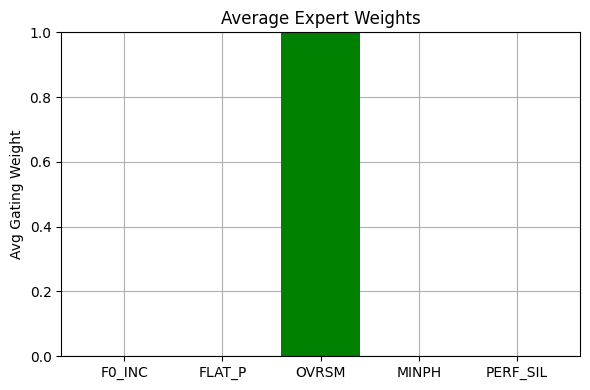

In [47]:
plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/moe_first_trial_5_experts_OVERSMOOTH_gating_mean_fake.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'], 
    color='green'
)

### Minimum Phase

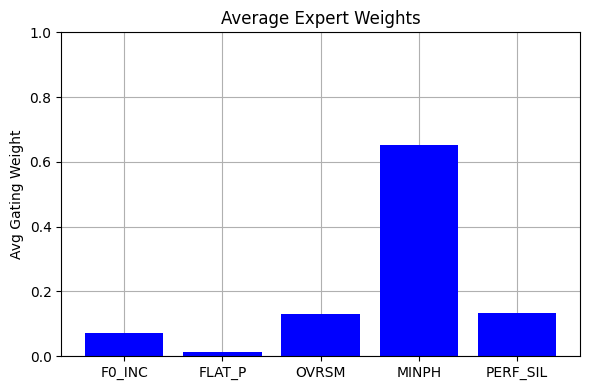

In [48]:
# 1000 bonafide + 1000 manipulated data (from EVAL SET)
# AUC: 100.00%, EER: 0.22%

plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/moe_first_trial_5_experts_MIN_PHASE_gating_mean_global.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL']
)

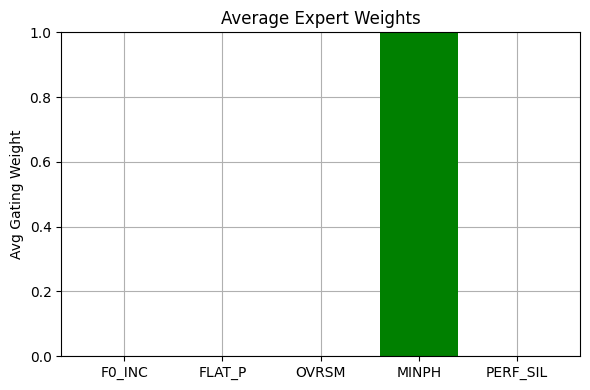

In [49]:
plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/moe_first_trial_5_experts_MIN_PHASE_gating_mean_fake.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'], 
    color='green'
)

### Perfect Silences

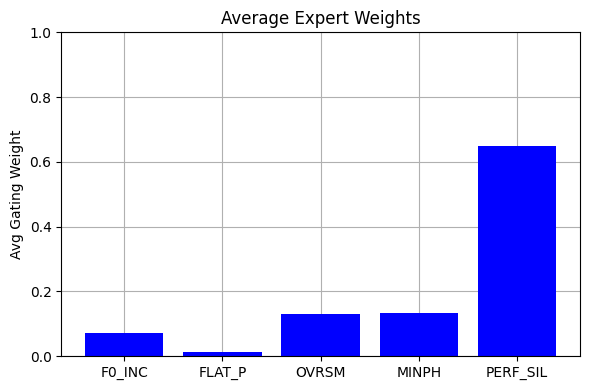

In [50]:
# 1000 bonafide + 1000 manipulated data (from EVAL SET)
# AUC: 99.99%, EER: 0.22%

plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/moe_first_trial_5_experts_PERF_SIL_gating_mean_global.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL']
)

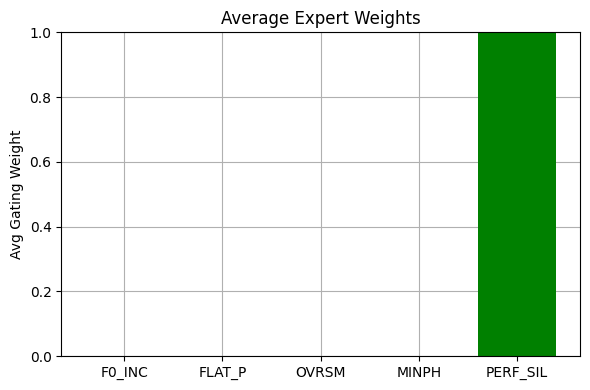

In [51]:
plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/moe_first_trial_5_experts_PERF_SIL_gating_mean_fake.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'], 
    color='green'
)

## One target generator at a time

### Flat Pitch

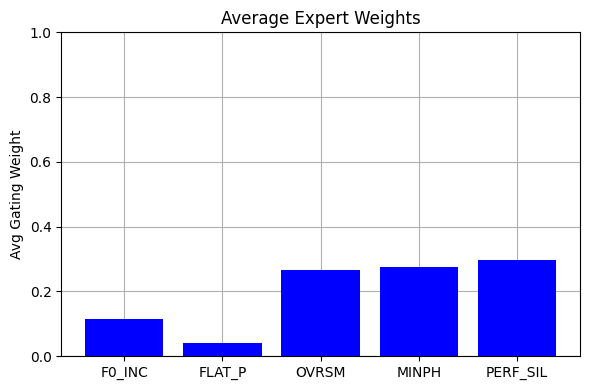

In [27]:
# 1000 bonafide (from ALL SETS) + 1000 deepfake data 
# AUC: 64.90%, EER: 39.43%

plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/moe_first_trial_5_experts_A04_gating_mean_global.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL']
)

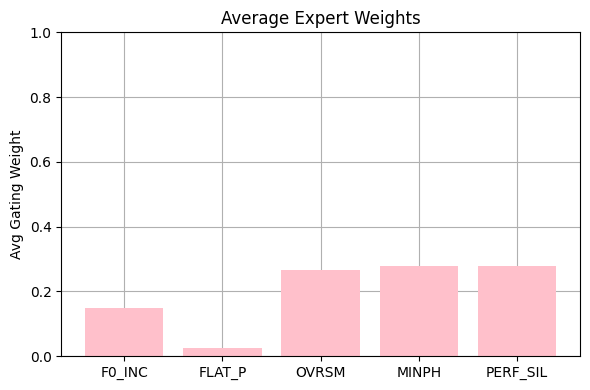

In [28]:
plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/moe_first_trial_5_experts_A04_gating_mean_real.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'],
    color='pink'
)

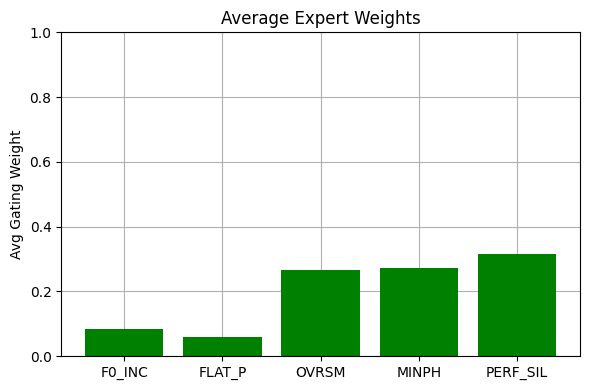

In [29]:
plot_5_expert_weights(
    "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck/moe_first_trial_5_experts_A04_gating_mean_fake.npy",
    expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'],
    color='green'
)